# Toxoplasma gondii prediction beyond NHANES: public datasets with exposure questions

**Why:** NHANES-only models plateau at ROC-AUC ≈ 0.74 (`toxo_max_score.ipynb`), because NHANES never asked the questions that
matter most: contact with cats, undercooked meat, unboiled water, soil. This notebook tests whether datasets that **do** ask them
can reach ROC-AUC ≥ 0.80.

**How the datasets were found (reproducible):**
1. Europe PMC search: Toxoplasma/toxoplasmosis + seroprevalence / risk factors / seropositivity, open access, with supplementary files, 2010-2026: **335 papers**
2. All supplementary files downloaded and every table opened automatically (`scripts/` search code in this notebook's appendix)
3. Kept: human studies whose supplement contains **one row per participant** with a Toxoplasma IgG result and questionnaire variables
4. Result: **9 usable datasets** (all CC BY open access). Every one is reported below, not only the ones that score well.

**Rules (same as before):** Toxoplasma test results other than the IgG label (IgM, ELISA index, rapid test, avidity, "ever had toxo")
are never used as inputs. Fixed model settings (no tuning per dataset). Scores are 5-fold cross-validation repeated 20 times.

In [1]:
import os, sys, warnings
if os.path.basename(os.getcwd()) == 'research_r':
    os.chdir('..')
sys.path.insert(0, 'scripts')
os.environ['PYTHONWARNINGS'] = 'ignore'
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from joblib import Parallel, delayed
from sklearn.metrics import roc_auc_score, roc_curve, confusion_matrix
from sklearn.model_selection import RepeatedStratifiedKFold

import external_datasets as ed
import eval_external as ev
import transfer_external as tx

pd.set_option('display.width', 220); pd.set_option('display.max_colwidth', 70)
INK, INK_2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
BLUE, ORANGE, AQUA, REFERENCE = '#2a78d6', '#eb6834', '#1baf7a', '#8a8985'
plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK_2, 'axes.titlecolor': INK,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'axes.axisbelow': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': INK_2, 'ytick.color': INK_2, 'text.color': INK,
    'font.size': 10, 'legend.frameon': False, 'figure.dpi': 110,
})

data = ed.load_all()          # downloads each paper's supplementary file from Europe PMC on first run
overview = pd.DataFrame([{'dataset': k, 'setting': info['setting'], 'source': info['cite'], 'DOI': info['doi'],
                          'n': len(y), 'positive': int(y.sum()), 'positive %': round(100 * y.mean(), 1),
                          'questionnaire variables': X.shape[1]} for k, (X, y, info) in data.items()])
display(overview)

,dataset,setting,source,DOI,n,positive,positive %,questionnaire variables
0,indonesia_pregnant,"Pregnant women, Makassar, Indonesia","Polanunu, Wahyuni & Hamid 2021, PLoS One",10.1371/journal.pone.0245572,182,60,33.0,17
1,cameroon_hiv,"People living with HIV, Bamenda, Cameroon",PLoS One 2021,10.1371/journal.pone.0256947,325,164,50.5,20
2,china_women,"Women with gynaecological tumour + matched controls, eastern China",PeerJ 2022,10.7717/peerj.14569,920,69,7.5,12
3,myanmar_slaughter,"Slaughterhouse workers, Yangon, Myanmar",PLoS One 2023,10.1371/journal.pone.0284352,139,78,56.1,46
4,iran_suicide,"Suicide attempters + controls, Lorestan, Iran",BMC Infect Dis 2025,10.1186/s12879-025-11200-1,500,153,30.6,12
5,philippines_cebu,"General population, Cebu, Philippines",PLoS One 2019,10.1371/journal.pone.0217989,924,244,26.4,16
6,thai_border_pregnant,"Migrant/refugee pregnant women, Thailand-Myanmar border",Am J Trop Med Hyg 2017,10.4269/ajtmh.16-0999,199,62,31.2,18
7,brazil_homeless,"Homeless persons, Sao Paulo, Brazil",Front Public Health 2020,10.3389/fpubh.2020.580637,120,43,35.8,43
8,ghana_sickle_cell,"Sickle cell disease patients, Ho, Ghana",PLoS One 2026,10.1371/journal.pone.0346155,156,83,53.2,10


---
## 1. Every dataset, three models
LogReg = logistic regression; RandomForest and XGBoost with small, fixed settings. AUC = mean of 20 repeats of 5-fold CV;
the range is the 2.5-97.5 percentile over repeats.

In [2]:
jobs = [(k, X, y, m) for k, (X, y, _) in data.items() for m in ev.MODELS]
out = Parallel(n_jobs=-1)(delayed(ev.run)(*j) for j in jobs)
res = pd.DataFrame([{'dataset': k, 'model': m, 'CV AUC': a.mean(), 'low': np.percentile(a, 2.5), 'high': np.percentile(a, 97.5)}
                    for k, m, a in out])
grid = res.pivot(index='dataset', columns='model', values='CV AUC').loc[overview['dataset']]
grid['best'] = grid.max(axis=1)
grid = grid.join(overview.set_index('dataset')[['n', 'positive %']])
display(grid.sort_values('best', ascending=False).round(3))
print(f"Datasets reaching ROC-AUC >= 0.80 with at least one model: {int((grid['best'] >= 0.8).sum())} of {len(grid)}")

,LogReg,RandomForest,XGBoost,best,n,positive %
dataset,,,,,,
china_women,0.846,0.895,0.867,0.895,920,7.5
indonesia_pregnant,0.870,0.864,0.875,0.875,182,33.0
ghana_sickle_cell,0.714,0.684,0.654,0.714,156,53.2
philippines_cebu,0.602,0.691,0.687,0.691,924,26.4
myanmar_slaughter,0.676,0.655,0.629,0.676,139,56.1
cameroon_hiv,0.648,0.626,0.626,0.648,325,50.5
iran_suicide,0.634,0.633,0.637,0.637,500,30.6
thai_border_pregnant,0.512,0.565,0.511,0.565,199,31.2
brazil_homeless,0.416,0.377,0.421,0.421,120,35.8


Datasets reaching ROC-AUC >= 0.80 with at least one model: 2 of 9


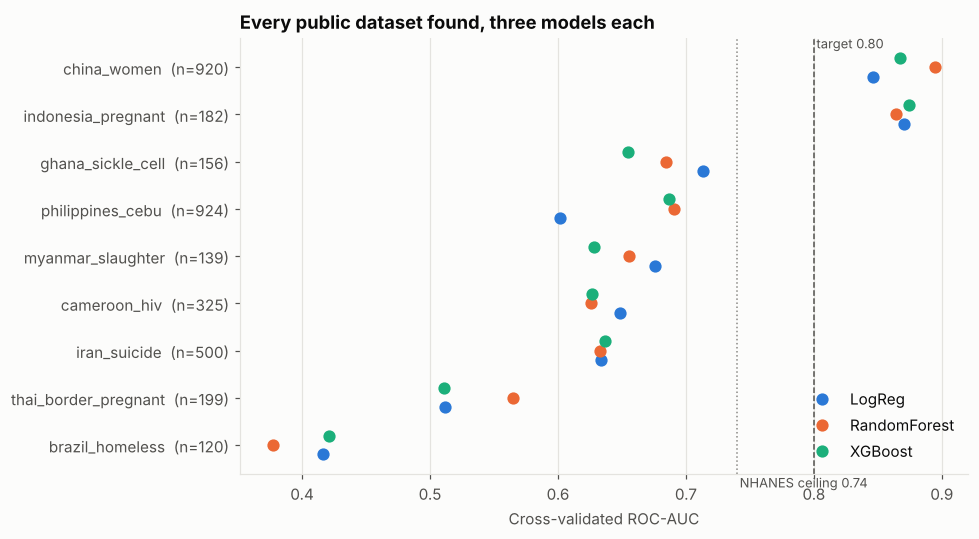

In [3]:
g = grid.sort_values('best')
fig, ax = plt.subplots(figsize=(9, 5))
yy = np.arange(len(g))
for m, color, off in [('LogReg', BLUE, -0.2), ('RandomForest', ORANGE, 0), ('XGBoost', AQUA, 0.2)]:
    ax.plot(g[m], yy + off, 'o', ms=7, color=color, label=m)
ax.axvline(0.8, color=INK_2, ls='--', lw=1)
ax.text(0.802, len(g) - 0.6, 'target 0.80', color=INK_2, fontsize=8.5)
ax.axvline(0.74, color=REFERENCE, ls=':', lw=1)
ax.text(0.742, -0.9, 'NHANES ceiling 0.74', color=INK_2, fontsize=8.5)
ax.set_yticks(yy)
ax.set_yticklabels([f"{d}  (n={int(n)})" for d, n in zip(g.index, g['n'])])
ax.set_xlabel('Cross-validated ROC-AUC')
ax.set_title('Every public dataset found, three models each')
ax.legend(loc='lower right')
ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

---
## 2. Indonesia: pregnant women in Makassar (Polanunu, Wahyuni & Hamid, PLoS One 2021)
The most relevant dataset for this project: Indonesian, 182 women, 33% positive, ELISA IgG. It asked about cat contact, litter-box cleaning,
soil, chicken satay (grilled, often undercooked chicken), raw vegetables and unboiled water.

In [4]:
X, y, info = data['indonesia_pregnant']
rows = []
for c in X.columns:
    if set(X[c].dropna().unique()) <= {0.0, 1.0}:
        rows.append({'question': c, 'n yes': int((X[c] == 1).sum()), 'positive % if yes': round(100 * y[X[c] == 1].mean(), 1),
                     'positive % if no': round(100 * y[X[c] == 0].mean(), 1), 'AUC alone': round(roc_auc_score(y, X[c]), 3)})
display(pd.DataFrame(rows).sort_values('AUC alone', ascending=False))


def oof_pred(Xs, ys, model, repeats=20):
    rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=repeats, random_state=42)
    p = np.zeros(len(ys))
    for tr, va in rskf.split(Xs, ys):
        p[va] += ev.MODELS[model]().fit(Xs.iloc[tr], ys.iloc[tr]).predict_proba(Xs.iloc[va])[:, 1] / repeats
    return p


def boot_ci(ys, p, n=2000, seed=42):
    rng = np.random.default_rng(seed); ys = np.asarray(ys); b = []
    while len(b) < n:
        i = rng.integers(0, len(ys), len(ys))
        if 0 < ys[i].sum() < len(i):
            b.append(roc_auc_score(ys[i], p[i]))
    return np.percentile(b, [2.5, 97.5])


MINI = ['cat_contact', 'eats_chicken_satay', 'unboiled_water', 'soil_contact']
indo = {}
for label, cols, model in [('all 17 questions, LogReg', list(X.columns), 'LogReg'),
                           ('all 17 questions, XGBoost', list(X.columns), 'XGBoost'),
                           ('4 questions (cat, satay, unboiled water, soil), LogReg', MINI, 'LogReg')]:
    p = oof_pred(X[cols], y, model)
    lo, hi = boot_ci(y, p)
    fpr, tpr, thr = roc_curve(y, p); t = thr[np.argmax(tpr - fpr)]
    tn, fp, fn, tp = confusion_matrix(y, (p >= t).astype(int)).ravel()
    indo[label] = p
    print(f'{label:58} AUC {roc_auc_score(y, p):.3f} (95% CI {lo:.3f}-{hi:.3f}) | sensitivity {tp/(tp+fn):.0%} '
          f'specificity {tn/(tn+fp):.0%} accuracy {(tp+tn)/len(y):.0%}')
print('Note: the threshold here is picked on the same out-of-fold predictions, so sensitivity/specificity are slightly optimistic; the AUC is not affected.')

,question,n yes,positive % if yes,positive % if no,AUC alone
6,eats_chicken_satay,94,53.2,11.4,0.736
3,cat_contact,49,71.4,18.8,0.734
8,unboiled_water,122,45.1,8.3,0.684
4,cleans_litterbox,18,61.1,29.9,0.563
5,soil_contact,25,48.0,30.6,0.547
7,raw_vegetables,98,36.7,28.6,0.546
2,cat_owner,24,45.8,31.0,0.538
1,employed,37,37.8,31.7,0.522
0,abortion_history,30,36.7,32.2,0.514


all 17 questions, LogReg                                   AUC 0.878 (95% CI 0.829-0.924) | sensitivity 90% specificity 73% accuracy 79%


all 17 questions, XGBoost                                  AUC 0.881 (95% CI 0.831-0.925) | sensitivity 92% specificity 75% accuracy 80%


4 questions (cat, satay, unboiled water, soil), LogReg     AUC 0.803 (95% CI 0.732-0.868) | sensitivity 90% specificity 75% accuracy 80%
Note: the threshold here is picked on the same out-of-fold predictions, so sensitivity/specificity are slightly optimistic; the AUC is not affected.


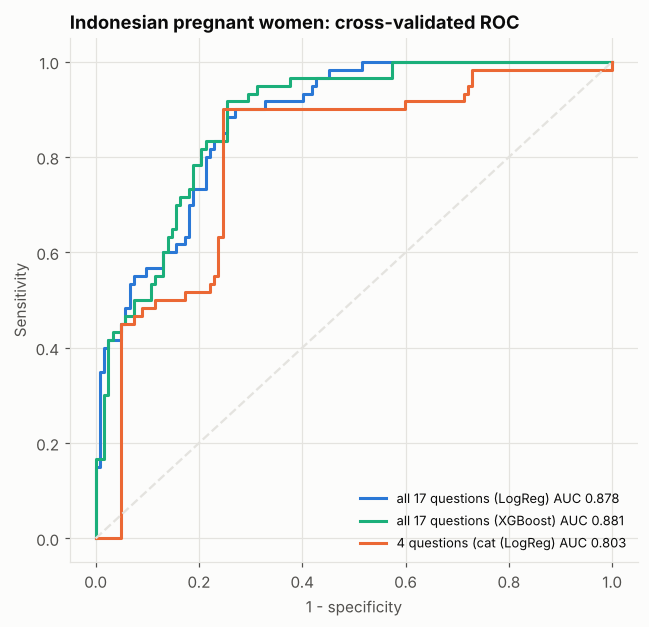

In [5]:
fig, ax = plt.subplots(figsize=(6, 5.8))
for (label, p), color in zip(indo.items(), [BLUE, AQUA, ORANGE]):
    fpr, tpr, _ = roc_curve(y, p)
    ax.plot(fpr, tpr, lw=2, color=color, label=f'{label.split(",")[0]} ({label.split(", ")[-1]}) AUC {roc_auc_score(y, p):.3f}')
ax.plot([0, 1], [0, 1], color=GRID, ls='--')
ax.set_xlabel('1 - specificity'); ax.set_ylabel('Sensitivity')
ax.set_title('Indonesian pregnant women: cross-validated ROC')
ax.legend(loc='lower right', fontsize=8.5)
plt.tight_layout(); plt.show()

---
## 3. China: women with a gynaecological tumour and matched controls (PeerJ 2022)
920 women, 8% positive. The design is case-control (tumour vs healthy), so the tumour flag itself predicts infection. Removing it is the
fair test.

In [6]:
X, y, _ = data['china_women']
for label, Xs, ys in [('with tumour flag', X, y), ('without tumour flag', X.drop(columns='tumour_patient'), y)]:
    for m in ['LogReg', 'RandomForest']:
        p = oof_pred(Xs, ys, m); lo, hi = boot_ci(ys, p)
        print(f'China {label:22} {m:12} AUC {roc_auc_score(ys, p):.3f} (95% CI {lo:.3f}-{hi:.3f})')
rows = []
for c in X.columns:
    if set(X[c].dropna().unique()) <= {0.0, 1.0}:
        rows.append({'question': c, 'positive % if yes': round(100 * y[X[c] == 1].mean(), 1),
                     'positive % if no': round(100 * y[X[c] == 0].mean(), 1), 'AUC alone': round(roc_auc_score(y, X[c]), 3)})
display(pd.DataFrame(rows).sort_values('AUC alone', ascending=False))

China with tumour flag       LogReg       AUC 0.850 (95% CI 0.807-0.891)


China with tumour flag       RandomForest AUC 0.900 (95% CI 0.872-0.926)


China without tumour flag    LogReg       AUC 0.805 (95% CI 0.753-0.857)


China without tumour flag    RandomForest AUC 0.861 (95% CI 0.821-0.899)


,question,positive % if yes,positive % if no,AUC alone
2,cat_contact,18.8,3.0,0.731
10,farmer,11.1,1.2,0.666
0,tumour_patient,11.7,3.3,0.653
7,soil_contact,11.1,5.4,0.595
5,raw_meat,9.7,6.9,0.532
3,dog_contact,8.5,7.0,0.525
9,abortion_history,8.8,7.2,0.520
1,rural,7.4,7.6,0.497
4,swine_contact,6.1,7.8,0.481
8,drinking_water_flag,6.3,8.3,0.465


---
## 4. Does a model travel? Leave-one-study-out
The same questions (cat, raw/undercooked meat, soil, raw vegetables, untreated water, age) were harmonised across the 9 studies. A
logistic regression is trained on 8 studies and scored on the 9th, which it has never seen.

In [7]:
H = tx.harmonise(data)
rows = []
for s in H['study'].unique():
    tr, te = H[H.study != s], H[H.study == s]
    m = tx.LogisticRegression(C=1.0, max_iter=5000).fit(tx.design(tr), tr['y'])
    asked = [q for q in tx.MAP if te[q].notna().any()]
    rows.append({'held-out study': s, 'n': len(te), 'questions it asked': ', '.join(asked),
                 'transfer AUC': round(roc_auc_score(te['y'], m.predict_proba(tx.design(te))[:, 1]), 3)})
transfer = pd.DataFrame(rows).sort_values('transfer AUC', ascending=False)
display(transfer)

,held-out study,n,questions it asked,transfer AUC
0,indonesia_pregnant,182,"cat, raw_or_undercooked_meat, soil, raw_vegetables, untreated_wate...",0.821
2,china_women,920,"cat, raw_or_undercooked_meat, soil, raw_vegetables, age",0.694
8,ghana_sickle_cell,156,"cat, raw_or_undercooked_meat, age",0.597
1,cameroon_hiv,325,"cat, raw_or_undercooked_meat, soil, raw_vegetables, untreated_wate...",0.584
6,thai_border_pregnant,199,age,0.578
5,philippines_cebu,924,"cat, age",0.550
4,iran_suicide,500,"cat, raw_or_undercooked_meat",0.496
3,myanmar_slaughter,139,"raw_or_undercooked_meat, soil, age",0.485
7,brazil_homeless,120,"cat, age",0.439


---
## 5. Summary

In [8]:
line = '=' * 78
print(line)
print('  CAN TOXOPLASMA PREDICTION REACH ROC-AUC 0.80?')
print(line)
print('  NHANES only (all 5,310 variables, best model)                   : 0.74 ceiling')
for k, r in grid.sort_values('best', ascending=False).iterrows():
    flag = '  <-- >= 0.80' if r['best'] >= 0.8 else ''
    print(f"  {k:22} n={int(r['n']):4d}  best CV AUC {r['best']:.3f}{flag}")
print(line)

  CAN TOXOPLASMA PREDICTION REACH ROC-AUC 0.80?
  NHANES only (all 5,310 variables, best model)                   : 0.74 ceiling
  china_women            n= 920  best CV AUC 0.895  <-- >= 0.80
  indonesia_pregnant     n= 182  best CV AUC 0.875  <-- >= 0.80
  ghana_sickle_cell      n= 156  best CV AUC 0.714
  philippines_cebu       n= 924  best CV AUC 0.691
  myanmar_slaughter      n= 139  best CV AUC 0.676
  cameroon_hiv           n= 325  best CV AUC 0.648
  iran_suicide           n= 500  best CV AUC 0.637
  thai_border_pregnant   n= 199  best CV AUC 0.565
  brazil_homeless        n= 120  best CV AUC 0.421


### What the numbers say
- **Yes, 0.80 is reachable, but only with direct exposure questions in a population where those exposures are common.**
  Indonesian pregnant women reach about **0.88** (17 questions, 95% CI 0.83-0.92) and about **0.80 with just four questions**
  (cat contact, chicken satay, unboiled water, soil; 95% CI 0.73-0.87). Chinese women reach 0.81-0.86 without the tumour flag.
- **It is not automatic.** Seven of nine datasets stay at 0.42-0.71. They either did not ask about cats, meat and water (Thailand,
  Brazil, Philippines) or the exposure was too common or too rare to separate people (Cameroon, Iran, Myanmar, Ghana).
- **The Indonesian model transfers:** trained only on the other eight studies, it still scores 0.82 on the Makassar women.
- **Caveats for the paper:** these are small studies (n = 182 and 920) with wide confidence intervals; scores come from cross-validation,
  not an external test cohort; different assays and populations mean the datasets cannot simply be pooled into one number.

### Recommendation
For an Indonesian screening tool, the evidence supports a **short questionnaire** built around cat contact, undercooked
(satay-style) poultry or meat, unboiled water and soil contact, validated on a new Indonesian cohort. The HIV-cohort questionnaire from the
earlier paper already contains most of these items. NHANES remains useful as a large background population, not as the source of a 0.8
model.